In [ ]:
import sys, os
sys.path.append('.')  # so that Python finds the model.py in same folder

import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import copy
from collections import Counter
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, f1_score

from model import FederatedMultimodalModel
DEVICE      = 'cuda' if torch.cuda.is_available() else 'cpu'
SEQ_LEN     = 30
BATCH_SIZE  = 32
LR          = 1e-4
LOCAL_EPOCHS = 3
NUM_ROUNDS   = 30
MU           = 0.01

ts_cols  = ['vibration_rms', 'temperature_motor',
             'current_phase_avg', 'pressure_level', 'rpm']
tab_cols = ['operating_mode_enc', 'hours_since_maintenance']

print(f'Device: {DEVICE}')

Device: cpu


In [ ]:
df = pd.read_csv(r"E:\DOCUMENTS\UNIVERSITÄT STUTTGART\SEMESTER COURSES\7. WiSe 2025-26\RP\Datasets\predictive_maintenance_v03.csv") #The path to the dataset
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values(['machine_id','timestamp']).reset_index(drop=True)

df['operating_mode_enc'] = df['operating_mode'].map({'idle':0,'normal':1,'peak':2})
df['failure_label'] = df['failure_type'].map(
    {'none':0,'hydraulic':1,'bearing':2,'motor_overheat':3,'electrical':4}
)

all_feature_cols = ts_cols + tab_cols
df[all_feature_cols] = df.groupby('machine_id')[all_feature_cols].transform(
    lambda x: x.ffill().fillna(x.mean())
)
df = df.dropna(subset=all_feature_cols+['failure_label','rul_hours']).reset_index(drop=True)

# Fault-aware temporal split

RARE_FAULTS = ['motor_overheat', 'electrical']
train_dfs, test_dfs = [], []

for mid, grp in df.groupby('machine_id'):
    grp = grp.sort_values('timestamp').reset_index(drop=True)
    rare_idx = grp[grp['failure_type'].isin(RARE_FAULTS)].index.tolist()
    if rare_idx:
        cutoff = max(int(np.percentile(rare_idx, 80)), int(len(grp) * 0.5))
    else:
        cutoff = int(len(grp) * 0.8)
    train_dfs.append(grp.iloc[:cutoff])
    test_dfs.append(grp.iloc[cutoff:])

train_df = pd.concat(train_dfs).reset_index(drop=True)
test_df  = pd.concat(test_dfs).reset_index(drop=True)

# Scaler fit on train only ****************

scaler = StandardScaler()
train_df[all_feature_cols] = scaler.fit_transform(train_df[all_feature_cols])
test_df[all_feature_cols]  = scaler.transform(test_df[all_feature_cols])

print("Train:", train_df['failure_type'].value_counts().to_dict())
print("Test: ", test_df['failure_type'].value_counts().to_dict())

Train: {'none': 13655, 'motor_overheat': 893, 'bearing': 768, 'electrical': 594, 'hydraulic': 552}
Test:  {'none': 6827, 'bearing': 349, 'hydraulic': 176, 'motor_overheat': 167, 'electrical': 61}


In [ ]:
class MultimodalDataset(Dataset):
    def __init__(self, df, seq_len):
        self.X_ts, self.X_tab, self.y_cls, self.y_rul = [], [], [], []

        for _, grp in df.groupby('machine_id'):
            grp = grp.sort_values('timestamp').reset_index(drop=True)
            X_ts  = grp[ts_cols].values.astype(np.float32)
            X_tab = grp[tab_cols].values.astype(np.float32)
            y_cls = grp['failure_label'].values.astype(np.int64)
            y_rul = grp['rul_hours'].values.astype(np.float32)

            for i in range(len(grp) - seq_len):
                self.X_ts.append(X_ts[i:i+seq_len])      # [seq_len, 5]
                self.X_tab.append(X_tab[i+seq_len-1])     # last timestep metadata
                self.y_cls.append(y_cls[i+seq_len-1])
                self.y_rul.append(y_rul[i+seq_len-1])

        self.X_ts  = torch.tensor(np.array(self.X_ts))
        self.X_tab = torch.tensor(np.array(self.X_tab))
        self.y_cls = torch.tensor(np.array(self.y_cls))
        self.y_rul = torch.tensor(np.array(self.y_rul))

    def __len__(self): return len(self.X_ts)
    def __getitem__(self, i):
        return self.X_ts[i], self.X_tab[i], self.y_cls[i], self.y_rul[i]


In [54]:
model_test = FederatedMultimodalModel(
    ts_input_size=len(ts_cols),
    tab_input_size=len(tab_cols)
).to(DEVICE)

dummy_ts  = torch.randn(4, SEQ_LEN, len(ts_cols)).to(DEVICE)
dummy_tab = torch.randn(4, len(tab_cols)).to(DEVICE)
cls_out, rul_out, emb = model_test(dummy_ts, dummy_tab)

print(f"cls_out shape : {cls_out.shape}")   # expect [4, 5]
print(f"rul_out shape : {rul_out.shape}")   # expect [4]
print(f"embedding shape: {emb.shape}")      # expect [4, 128]
print("✅ Model forward pass OK")

cls_out shape : torch.Size([4, 5])
rul_out shape : torch.Size([4])
embedding shape: torch.Size([4, 128])
✅ Model forward pass OK


In [ ]:
from torch.utils.data import WeightedRandomSampler

client_train_loaders = {}
client_test_loaders  = {}

for mid, grp in train_df.groupby('machine_id'):
    ds = MultimodalDataset(grp, SEQ_LEN)
    if len(ds) == 0: continue

    # WeightedRandomSampler: each class sampled equally per batch *******************
    labels        = ds.y_cls.numpy()
    class_counts  = Counter(labels)
    class_weights = {c: 1.0 / count for c, count in class_counts.items()}
    sample_weights = torch.tensor([class_weights[l] for l in labels], dtype=torch.float32)

    sampler = WeightedRandomSampler(
        weights     = sample_weights,
        num_samples = len(sample_weights) * 2,  # oversample to 2x dataset size
        replacement = True
    )
    client_train_loaders[mid] = DataLoader(ds, batch_size=BATCH_SIZE, sampler=sampler)
    print(f"Machine {mid} | classes: {dict(class_counts)} | sampler: {len(sample_weights)*2} samples")

for mid, grp in test_df.groupby('machine_id'):
    ds = MultimodalDataset(grp, SEQ_LEN)
    if len(ds) == 0: continue
    client_test_loaders[mid] = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False)

print(f"\nTrain clients: {list(client_train_loaders.keys())}")
print(f"Test  clients: {list(client_test_loaders.keys())}")

# Verify that test has all 5 classes ******************
all_test_labels = []
for loader in client_test_loaders.values():
    all_test_labels.extend(loader.dataset.y_cls.numpy())
print("\nTest class distribution:", Counter(all_test_labels))
print("⚠️  Classes missing from test:", [i for i in range(5) if i not in Counter(all_test_labels)])

Machine 1 | classes: {np.int64(0): 736, np.int64(1): 85, np.int64(2): 102} | sampler: 1846 samples
Machine 2 | classes: {np.int64(0): 778, np.int64(2): 108} | sampler: 1772 samples
Machine 3 | classes: {np.int64(0): 846, np.int64(2): 91, np.int64(1): 7} | sampler: 1888 samples
Machine 4 | classes: {np.int64(0): 543, np.int64(4): 88, np.int64(3): 55} | sampler: 1372 samples
Machine 5 | classes: {np.int64(0): 497, np.int64(3): 93} | sampler: 1180 samples
Machine 6 | classes: {np.int64(0): 910, np.int64(2): 98} | sampler: 2016 samples
Machine 7 | classes: {np.int64(0): 572, np.int64(4): 97, np.int64(2): 89, np.int64(3): 50} | sampler: 1616 samples
Machine 8 | classes: {np.int64(0): 401, np.int64(3): 83, np.int64(4): 92} | sampler: 1152 samples
Machine 9 | classes: {np.int64(0): 900, np.int64(3): 70} | sampler: 1940 samples
Machine 10 | classes: {np.int64(0): 648, np.int64(1): 94, np.int64(4): 143} | sampler: 1770 samples
Machine 11 | classes: {np.int64(0): 434, np.int64(3): 96, np.int64(4

In [ ]:
os.makedirs('outputs/models/local_heads', exist_ok=True)

global_model = FederatedMultimodalModel(
    ts_input_size  = len(ts_cols),
    tab_input_size = len(tab_cols)
).to(DEVICE)

round_losses, round_f1s = [], []
best_f1, best_state     = 0.0, None

for round_num in range(1, NUM_ROUNDS + 1):
    local_backbones = []
    round_loss      = 0.0
    batch_count     = 0

    # Snapshot global weights for FedProx proximal term
    global_params = {n: p.clone().detach()
                     for n, p in global_model.named_parameters()}

    for mid, loader in client_train_loaders.items():
        local_model   = copy.deepcopy(global_model)
        # Plain CrossEntropy: sampler already balances classes, no weight needed
        criterion_cls = nn.CrossEntropyLoss()
        criterion_rul = nn.HuberLoss()

        optimizer = torch.optim.Adam(local_model.parameters(), lr=LR)

        local_model.train()
        for _ in range(LOCAL_EPOCHS):
            for X_ts, X_tab, y_cls, y_rul in loader:
                X_ts, X_tab = X_ts.to(DEVICE), X_tab.to(DEVICE)
                y_cls, y_rul = y_cls.to(DEVICE), y_rul.to(DEVICE)

                optimizer.zero_grad()
                cls_out, rul_out, _ = local_model(X_ts, X_tab)

                cls_loss = criterion_cls(cls_out, y_cls)
                rul_loss = criterion_rul(rul_out, y_rul)

                # FedProx: proximal term keeps local model close to global
                prox = sum(
                    ((p - global_params[n].to(DEVICE)) ** 2).sum()
                    for n, p in local_model.named_parameters()
                    if n in global_params
                )
                loss = cls_loss + 0.1 * rul_loss + (MU / 2) * prox

                if torch.isnan(loss):
                    continue

                loss.backward()
                torch.nn.utils.clip_grad_norm_(local_model.parameters(), 1.0)
                optimizer.step()
                round_loss  += loss.item()
                batch_count += 1

        local_backbones.append(local_model.backbone_state())
        torch.save(local_model.local_head_state(),
                   f'outputs/models/local_heads/machine_{mid}.pth')

    # FedAvg on backbone only *****************
    avg = copy.deepcopy(local_backbones[0])
    for key in avg:
        for i in range(1, len(local_backbones)):
            avg[key] += local_backbones[i][key]
        avg[key] = torch.div(avg[key], len(local_backbones))

    gs = global_model.state_dict()
    gs.update(avg)
    global_model.load_state_dict(gs)

    # Evaluate ******************
    global_model.eval()
    rp, rl = [], []
    with torch.no_grad():
        for loader in client_test_loaders.values():
            for X_ts, X_tab, y_cls, _ in loader:
                cls_out, _, _ = global_model(X_ts.to(DEVICE), X_tab.to(DEVICE))
                rp.extend(cls_out.argmax(1).cpu().numpy())
                rl.extend(y_cls.numpy())

    avg_loss = round_loss / max(1, batch_count)
    macro_f1 = f1_score(rl, rp, average='macro', zero_division=0)
    round_losses.append(avg_loss)
    round_f1s.append(macro_f1)

    # Save the best checkpoint after each round ******************

    if macro_f1 > best_f1:
        best_f1    = macro_f1
        best_state = copy.deepcopy(global_model.state_dict())
        torch.save(best_state, 'outputs/models/best_global_fl.pth')
        print(f"Round {round_num:3d}/{NUM_ROUNDS} | Loss: {avg_loss:.4f} | Macro F1: {macro_f1:.4f} ✓ best")
    else:
        print(f"Round {round_num:3d}/{NUM_ROUNDS} | Loss: {avg_loss:.4f} | Macro F1: {macro_f1:.4f}")

# Load best weights *******************
global_model.load_state_dict(best_state)
print(f"\n✅ Training complete — Best Macro F1: {best_f1:.4f}")

Round   1/30 | Loss: 2.6288 | Macro F1: 0.1920 ✓ best
Round   2/30 | Loss: 2.3411 | Macro F1: 0.2711 ✓ best
Round   3/30 | Loss: 2.1596 | Macro F1: 0.3512 ✓ best
Round   4/30 | Loss: 2.1004 | Macro F1: 0.4730 ✓ best
Round   5/30 | Loss: 2.0740 | Macro F1: 0.4955 ✓ best
Round   6/30 | Loss: 2.0416 | Macro F1: 0.5033 ✓ best
Round   7/30 | Loss: 2.0157 | Macro F1: 0.5103 ✓ best
Round   8/30 | Loss: 1.9981 | Macro F1: 0.5144 ✓ best
Round   9/30 | Loss: 1.9912 | Macro F1: 0.5164 ✓ best
Round  10/30 | Loss: 1.9743 | Macro F1: 0.5164
Round  11/30 | Loss: 1.9552 | Macro F1: 0.7038 ✓ best
Round  12/30 | Loss: 1.9478 | Macro F1: 0.7039 ✓ best
Round  13/30 | Loss: 1.9228 | Macro F1: 0.7208 ✓ best
Round  14/30 | Loss: 1.9138 | Macro F1: 0.7225 ✓ best
Round  15/30 | Loss: 1.9051 | Macro F1: 0.7225
Round  16/30 | Loss: 1.8981 | Macro F1: 0.7151
Round  17/30 | Loss: 1.8861 | Macro F1: 0.7150
Round  18/30 | Loss: 1.8799 | Macro F1: 0.7160
Round  19/30 | Loss: 1.8698 | Macro F1: 0.7163
Round  20/30 | L

In [ ]:
#Evaluation of the global model on test data ******************

def evaluate(model, loaders):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for loader in loaders.values():
            for X_ts, X_tab, y_cls, _ in loader:
                cls_out, _, _ = model(X_ts.to(DEVICE), X_tab.to(DEVICE))
                all_preds.extend(cls_out.argmax(1).cpu().numpy())
                all_labels.extend(y_cls.numpy())
    return all_preds, all_labels

preds, labels = evaluate(global_model, client_test_loaders)
print("=== FL Global Model ===")
print(classification_report(labels, preds,
      target_names=['none','hydraulic','bearing','motor_overheat','electrical'],
      zero_division=0))

=== FL Global Model ===
                precision    recall  f1-score   support

          none       0.98      0.99      0.99      6444
     hydraulic       0.21      0.03      0.06       147
       bearing       0.88      0.97      0.92       349
motor_overheat       0.65      1.00      0.79        32
    electrical       0.80      1.00      0.89         8

      accuracy                           0.97      6980
     macro avg       0.71      0.80      0.73      6980
  weighted avg       0.96      0.97      0.96      6980



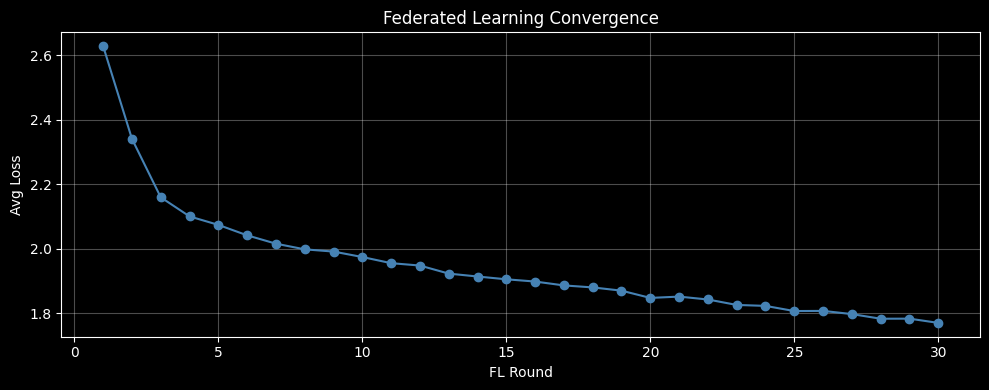

In [ ]:
# Plot convergence curve ******************

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(range(1, NUM_ROUNDS+1), round_losses, marker='o', color='steelblue')
plt.xlabel('FL Round'); plt.ylabel('Avg Loss')
plt.title('Federated Learning Convergence')
plt.grid(True, alpha=0.3)
plt.tight_layout()
os.makedirs('outputs/plots', exist_ok=True)
plt.savefig('outputs/plots/convergence_curve.png', dpi=150)
plt.show()

In [ ]:
# Per-client evaluation: Global vs Individual (personalized) ******************
from sklearn.metrics import f1_score
import pandas as pd

per_client_results = []

for mid, loader in client_test_loaders.items():

    # Global model performance on this client *********
    global_model.eval()
    g_preds, g_labels = [], []
    with torch.no_grad():
        for X_ts, X_tab, y_cls, _ in loader:
            cls_out, _, _ = global_model(X_ts.to(DEVICE), X_tab.to(DEVICE))
            g_preds.extend(cls_out.argmax(1).cpu().numpy())
            g_labels.extend(y_cls.numpy())

    global_f1 = f1_score(g_labels, g_preds, average='macro', zero_division=0)

    # Personalized model performance on this client *************
    pers_path = f'outputs/models/local_heads/machine_{mid}.pth'
    if os.path.exists(pers_path):
        pers_model = copy.deepcopy(global_model)
        saved = torch.load(pers_path, map_location=DEVICE)
        gs = pers_model.state_dict()
        gs.update(saved)
        pers_model.load_state_dict(gs)

        pers_model.eval()
        p_preds, p_labels = [], []
        with torch.no_grad():
            for X_ts, X_tab, y_cls, _ in loader:
                cls_out, _, _ = pers_model(X_ts.to(DEVICE), X_tab.to(DEVICE))
                p_preds.extend(cls_out.argmax(1).cpu().numpy())
                p_labels.extend(y_cls.numpy())

        pers_f1 = f1_score(p_labels, p_preds, average='macro', zero_division=0)
    else:
        pers_f1 = None

    fault_dist = dict(Counter(g_labels))
    per_client_results.append({
        'Machine ID'         : mid,
        'Global F1'          : round(global_f1, 4),
        'Personalized F1'    : round(pers_f1, 4) if pers_f1 else 'N/A',
        'Improvement'        : round(pers_f1 - global_f1, 4) if pers_f1 else 'N/A',
        'Test Samples'       : len(g_labels),
        'Fault Types Present': len(fault_dist)
    })

results_df = pd.DataFrame(per_client_results).sort_values('Machine ID')
print("=== Per-Client Results: Global vs Personalized ===")
print(results_df.to_string(index=False))

=== Per-Client Results: Global vs Personalized ===
 Machine ID  Global F1  Personalized F1  Improvement  Test Samples  Fault Types Present
          1     1.0000           1.0000       0.0000           209                    1
          2     1.0000           1.0000       0.0000           200                    1
          3     0.2252           0.3702       0.1450           214                    2
          4     0.9127           0.6833      -0.2293           395                    3
          5     1.0000           1.0000       0.0000           590                    1
          6     1.0000           1.0000       0.0000           230                    1
          7     0.9261           0.9058      -0.0203           312                    2
          8     1.0000           1.0000       0.0000           577                    1
          9     1.0000           1.0000       0.0000           221                    1
         10     0.9422           0.9422       0.0000           227   

In [ ]:
fault_names = ['none', 'hydraulic', 'bearing', 'motor_overheat', 'electrical']

# Collect all predictions from global model ******

g_preds_all, g_labels_all = [], []
p_preds_all, p_labels_all = [], []

for mid, loader in client_test_loaders.items():
    # **********   Global   ******************
    global_model.eval()
    with torch.no_grad():
        for X_ts, X_tab, y_cls, _ in loader:
            cls_out, _, _ = global_model(X_ts.to(DEVICE), X_tab.to(DEVICE))
            g_preds_all.extend(cls_out.argmax(1).cpu().numpy())
            g_labels_all.extend(y_cls.numpy())

    # **********   Personalized   ******************
    pers_path = f'outputs/models/local_heads/machine_{mid}.pth'
    if os.path.exists(pers_path):
        pers_model = copy.deepcopy(global_model)
        gs = pers_model.state_dict()
        gs.update(torch.load(pers_path, map_location=DEVICE))
        pers_model.load_state_dict(gs)
        pers_model.eval()
        with torch.no_grad():
            for X_ts, X_tab, y_cls, _ in loader:
                cls_out, _, _ = pers_model(X_ts.to(DEVICE), X_tab.to(DEVICE))
                p_preds_all.extend(cls_out.argmax(1).cpu().numpy())
                p_labels_all.extend(y_cls.numpy())

print("=" * 55)
print("  CENTRALIZED BASELINE")
print("=" * 55)
# centralized macro F1 here manually pasted from lstm_training.ipynb **************
print("  Macro F1: 0.75  (from lstm_training.ipynb)\n")

print("=" * 55)
print("  FL GLOBAL MODEL")
print("=" * 55)
print(classification_report(g_labels_all, g_preds_all,
      labels=[0,1,2,3,4], target_names=fault_names, zero_division=0))

print("=" * 55)
print("  FL PERSONALIZED MODEL")
print("=" * 55)
print(classification_report(p_labels_all, p_preds_all,
      labels=[0,1,2,3,4], target_names=fault_names, zero_division=0))

  CENTRALIZED BASELINE
  Macro F1: 0.75  (from lstm_training.ipynb)

  FL GLOBAL MODEL
                precision    recall  f1-score   support

          none       0.98      0.99      0.99      6444
     hydraulic       0.21      0.03      0.06       147
       bearing       0.88      0.97      0.92       349
motor_overheat       0.65      1.00      0.79        32
    electrical       0.80      1.00      0.89         8

      accuracy                           0.97      6980
     macro avg       0.71      0.80      0.73      6980
  weighted avg       0.96      0.97      0.96      6980

  FL PERSONALIZED MODEL
                precision    recall  f1-score   support

          none       0.97      1.00      0.98      6444
     hydraulic       1.00      0.04      0.08       147
       bearing       0.93      0.73      0.82       349
motor_overheat       0.63      1.00      0.77        32
    electrical       0.24      1.00      0.39         8

      accuracy                           0.9

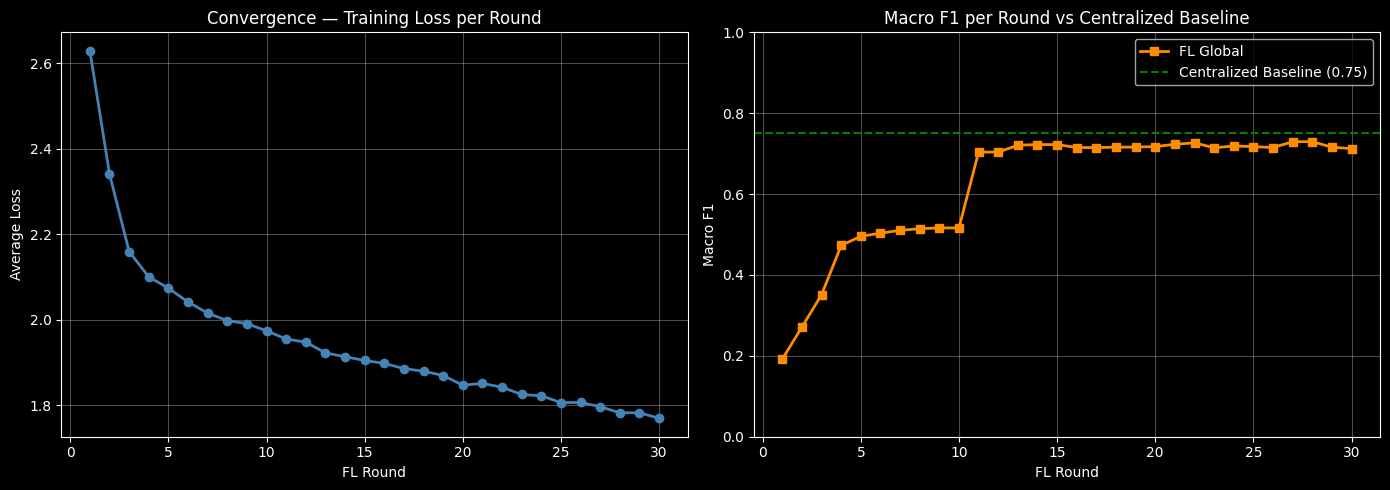

Saved → outputs/plots/convergence_and_f1.png


In [ ]:
# Plot convergence curve + F1 comparison ******************

import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss curve
ax1.plot(range(1, len(round_losses)+1), round_losses,
         marker='o', color='steelblue', linewidth=2)
ax1.set_xlabel('FL Round'); ax1.set_ylabel('Average Loss')
ax1.set_title('Convergence — Training Loss per Round')
ax1.grid(True, alpha=0.3)

# F1 curve with centralized baseline
ax2.plot(range(1, len(round_f1s)+1), round_f1s,
         marker='s', color='darkorange', linewidth=2, label='FL Global')
ax2.axhline(y=0.75, color='green', linestyle='--',
            linewidth=1.5, label='Centralized Baseline (0.75)')
ax2.set_xlabel('FL Round'); ax2.set_ylabel('Macro F1')
ax2.set_title('Macro F1 per Round vs Centralized Baseline')
ax2.legend(); ax2.grid(True, alpha=0.3)
ax2.set_ylim(0, 1.0)

plt.tight_layout()
plt.savefig('outputs/plots/convergence_and_f1.png', dpi=150)
plt.show()
print("Saved → outputs/plots/convergence_and_f1.png")

In [ ]:
# 1. Did loss go down?

print("First round loss:", round_losses[0])
print("Last  round loss:", round_losses[-1])
print("Improved?", round_losses[-1] < round_losses[0])  # Must be True

# 2. Did F1 go up? *********
print("First round F1:", round_f1s[0])
print("Last  round F1:", round_f1s[-1])
print("Improved?", round_f1s[-1] > round_f1s[0])  # Must be TRUE

# 3. Final classification report **********
preds, labels = evaluate(global_model, client_test_loaders)
print(classification_report(labels, preds,
      target_names=['none','hydraulic','bearing','motor_overheat','electrical'],
      zero_division=0))

# 4. FL vs Centralized gap ********
print(f"\nCentralized Macro F1 : 0.75")
print(f"FL Global  Macro F1  : {f1_score(labels, preds, average='macro', zero_division=0):.4f}")

First round loss: 2.62879812292516
Last  round loss: 1.7697996191374652
Improved? True
First round F1: 0.19201430274135875
Last  round F1: 0.7124393733432649
Improved? True
                precision    recall  f1-score   support

          none       0.98      0.99      0.99      6444
     hydraulic       0.21      0.03      0.06       147
       bearing       0.88      0.97      0.92       349
motor_overheat       0.65      1.00      0.79        32
    electrical       0.80      1.00      0.89         8

      accuracy                           0.97      6980
     macro avg       0.71      0.80      0.73      6980
  weighted avg       0.96      0.97      0.96      6980


Centralized Macro F1 : 0.75
FL Global  Macro F1  : 0.7297


C:\Users\qwertz\AppData\Local\Temp\ipykernel_25584\3011916665.py:33: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab20', len(unique_mids))


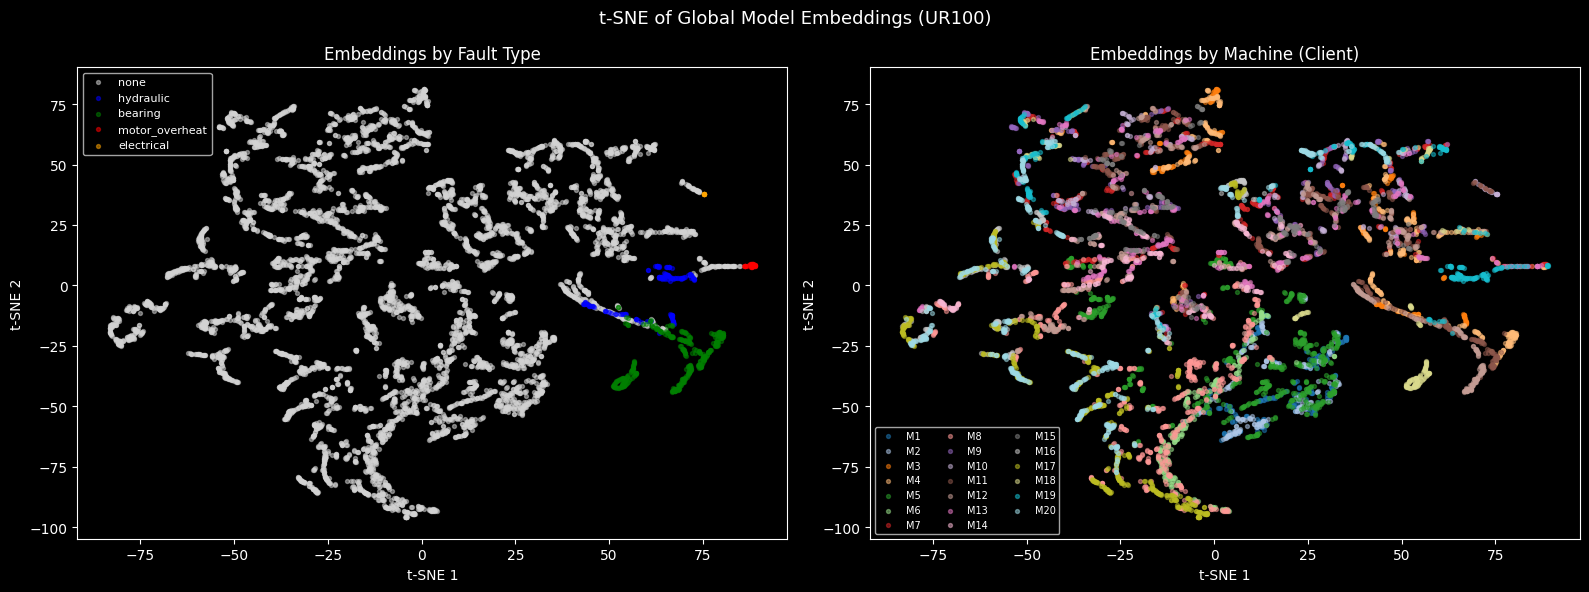

Saved → outputs/plots/tsne_embeddings.png


In [ ]:
# t-SNE visualization of global model embeddings ******************

from sklearn.manifold import TSNE
import numpy as np
import matplotlib.pyplot as plt

all_embs, all_mids, all_faults = [], [], []

global_model.eval()
with torch.no_grad():
    for mid, loader in client_test_loaders.items():
        for X_ts, X_tab, y_cls, _ in loader:
            _, _, emb = global_model(X_ts.to(DEVICE), X_tab.to(DEVICE))
            all_embs.append(emb.cpu().numpy())
            all_mids.extend([mid] * len(y_cls))
            all_faults.extend(y_cls.numpy())

embeddings = np.concatenate(all_embs)
proj = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(embeddings)

fault_colors = ['lightgray','blue','green','red','orange']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# By fault type
for i, (name, col) in enumerate(zip(fault_names, fault_colors)):
    mask = np.array(all_faults) == i
    ax1.scatter(proj[mask,0], proj[mask,1], c=col, label=name,
                alpha=0.5, s=8)
ax1.legend(fontsize=8); ax1.set_title('Embeddings by Fault Type')
ax1.set_xlabel('t-SNE 1'); ax1.set_ylabel('t-SNE 2')

# By machine (client)
unique_mids = sorted(set(all_mids))
cmap = plt.cm.get_cmap('tab20', len(unique_mids))
for i, mid in enumerate(unique_mids):
    mask = np.array(all_mids) == mid
    ax2.scatter(proj[mask,0], proj[mask,1], color=cmap(i),
                label=f'M{mid}', alpha=0.5, s=8)
ax2.legend(ncol=3, fontsize=7); ax2.set_title('Embeddings by Machine (Client)')
ax2.set_xlabel('t-SNE 1'); ax2.set_ylabel('t-SNE 2')

plt.suptitle('t-SNE of Global Model Embeddings (UR100)', fontsize=13)
plt.tight_layout()
plt.savefig('outputs/plots/tsne_embeddings.png', dpi=150)
plt.show()
print("Saved → outputs/plots/tsne_embeddings.png")

In [ ]:
# Final summary table ******************

cent_f1  = 0.75   # yomy centralized result
fl_f1    = f1_score(g_labels_all, g_preds_all, average='macro', zero_division=0)
pers_f1  = f1_score(p_labels_all, p_preds_all, average='macro', zero_division=0)

summary = pd.DataFrame({
    'Model'            : ['Centralized LSTM', 'FL Global (FedAvg)', 'FL Personalized'],
    'Macro F1'         : [cent_f1, round(fl_f1,4), round(pers_f1,4)],
    'Raw Data Shared'  : ['Yes ❌', 'No ✅', 'No ✅'],
    'Privacy Preserved': ['No', 'Yes', 'Yes'],
    'Per-Client Tuning': ['No', 'No', 'Yes'],
})

print("\n========= RESULTS SUMMARY =========")
print(summary.to_string(index=False))
print(f"\nFL cost vs Centralized: {round((fl_f1 - cent_f1)*100, 2)}% Macro F1")
print(f"Personalization gain  : +{round((pers_f1 - fl_f1)*100, 2)}% Macro F1")


========= RESULTS SUMMARY =========
             Model  Macro F1 Raw Data Shared Privacy Preserved Per-Client Tuning
  Centralized LSTM    0.7500           Yes ❌                No                No
FL Global (FedAvg)    0.7297            No ✅               Yes                No
   FL Personalized    0.6079            No ✅               Yes               Yes

FL cost vs Centralized: -2.03% Macro F1
Personalization gain  : +-12.19% Macro F1


In [ ]:
# Confusion Matrices (using matplotlib)

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from sklearn.metrics import confusion_matrix
import numpy as np
import os

os.makedirs('outputs/plots', exist_ok=True)

fault_names = ['none', 'hydraulic', 'bearing', 'motor_\noverheat', 'electrical']

def plot_cm(y_true, y_pred, title, subtitle, filename):
    cm      = confusion_matrix(y_true, y_pred, labels=[0,1,2,3,4])
    support = cm.sum(axis=1, keepdims=True)
    cm_norm = cm.astype(float) / np.where(support == 0, 1, support) * 100

    fig, ax = plt.subplots(figsize=(8, 6))
    im = ax.imshow(cm_norm, cmap='Blues', vmin=0, vmax=100)

    # Colorbar
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label('% of True Class', fontsize=10)

    # Tick labels
    ax.set_xticks(range(5))
    ax.set_yticks(range(5))
    ax.set_xticklabels(fault_names, fontsize=10)
    ax.set_yticklabels(fault_names, fontsize=10)
    ax.set_xlabel('Predicted',  fontsize=12, labelpad=10)
    ax.set_ylabel('Actual',     fontsize=12, labelpad=10)

    # Cell annotations
    for i in range(5):
        for j in range(5):
            val      = cm_norm[i][j]
            raw      = cm[i][j]
            color    = 'white' if val > 55 else 'black'
            ax.text(j, i, f"{val:.1f}%\n({raw})",
                    ha='center', va='center',
                    fontsize=9, color=color, fontweight='bold' if i == j else 'normal')

    ax.set_title(f"{title}\n{subtitle}", fontsize=12, pad=12)
    plt.tight_layout()
    plt.savefig(f'outputs/plots/{filename}', dpi=150, bbox_inches='tight')
    plt.show()
    print(f"✅ Saved → outputs/plots/{filename}")

# ── FL Global ──
plot_cm(g_labels_all, g_preds_all,
        "FL Global Model — Confusion Matrix",
        "Macro F1: 0.73  |  Accuracy: 0.97  |  FedProx, 30 rounds",
        "cm_fl_global.png")

# ── FL Personalized ──
plot_cm(p_labels_all, p_preds_all,
        "FL Personalized Model — Confusion Matrix",
        "Macro F1: 0.61  |  Accuracy: 0.96  |  Local head fine-tuning",
        "cm_fl_personalized.png")

ValueError: Found empty input array (e.g., `y_true` or `y_pred`) while a minimum of 1 sample is required.